# Which stars belong together?

*Galactic archaeology with Gaia and Rubin*  
**Ani Chiti · Ioana Ciucă · Stanford PHYSICS 367**

On Monday, Ani showed how to use imaging to select stars in a dwarf galaxy based on their color and brightness. Suppose we start instead with a group of stars that have similar proper motions. Would you expect them to lie close together on the sky, and what might their colours and magnitudes tell you about whether they belong together?

We’ll spend about 45 minutes trying this with Gaia, first on two star clusters, the Pleiades and M5, and then on a stellar stream called GD-1. If you have another 10 minutes at the end, there are two candidate stream stars to look for in Rubin images.

If you’re coming to the Gaia DR4 Sprint at KIPAC on December 2–4, we’d like to hear what you’re planning to work on. Here are the [Sprint details](https://kipac.stanford.edu/events/kipac-workshops/kipac-gaia-dr4-x-agentic-ai-sprint-decoding-milky-way-stanford)!


## Warm-up (~5 min)

Pick two stars that look close together on the sky. Between you and your neighbour, what would you want to measure before calling them members of the same cluster?

| Gaia column | What it measures |
|---|---|
| `ra`, `dec` | Right ascension and declination in degrees. |
| `phot_g_mean_mag` | Apparent magnitude in Gaia’s broad *G* band. The smaller the magnitude, the brighter the star. A difference of 5 mag corresponds to a factor of 100 in flux. |
| `bp_rp` | The difference between the magnitudes measured by Gaia’s blue and red photometers (*BP* − *RP*). A larger value means a redder colour, which usually corresponds to a cooler star. |
| `pmra`, `pmdec` | The two components of proper motion, in milliarcseconds per year (mas/yr). Gaia includes the cos(dec) factor in `pmra`, so these columns give the angular motion across the sky in the east and north directions. |
| `parallax` | The apparent shift in a star’s position as Earth orbits the Sun, measured in milliarcseconds (mas). Closer stars have larger parallaxes. If the parallax is well measured, you can estimate the distance in kpc by dividing 1 by the parallax in mas. |
| `ruwe` | Renormalised unit weight error, a measure of how well a single-star model fits the astrometry. A value near 1 indicates a good fit, while a value above about 1.4 can flag a poor fit, as you might get for an unresolved binary. |

Keep the supplied `gaia_data/` folder beside the notebook and run the cells in order. The notebook reads the saved table whenever its query matches, and downloads a fresh copy from the ESA archive if it can’t find a match. You’ll need an internet connection the first time through with the supplied files.

Work through the questions with your neighbour before opening the answers.


<details>
<summary>Compare your answers</summary>

Two stars can look close together even if one is much farther away, so a good place to start is to ask whether their parallaxes agree within the measurement uncertainties. Members of the same cluster also travel through space together, which gives us a reason to compare their proper motions. We can check where the stars fall on a colour–magnitude diagram and, if we have spectra, what are their radial velocities and chemical abundances.

</details>


## Setup

Run the next three cells to import the Python libraries and define the functions we’ll use, including `gaia_sample`, which reads the saved Gaia table or queries the archive when we need a new one.

We’ll use the same three-step recipe for both clusters, so once you’ve tried it on the Pleiades you can use your own estimate of M5’s motion to pick out its stars.

1. **Select by proper motion.** The orange circle in `show_motion` marks the range of proper motions we’re willing to use for the cluster, and the stars inside it are our candidates.
2. **Check the sky map.** Find those same candidates in `show_sky`, where they’re marked in teal. Do they gather in one part of the field?
3. **Check the colour–magnitude diagram.** Do the candidates trace sequences in `show_cmd`? What other things can you look at to establish if these stars are part of the same structure? 

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': False,
    'figure.constrained_layout.use': True,
})

TEAL, ORANGE, GREY = '#007C83', '#C76D33', '#B7BEC5'

data_dir = Path('gaia_data')
data_dir.mkdir(exist_ok=True)

In [ ]:
GAIA_ROW_LIMIT = 50_000  # row limit for anonymous queries

def gaia_sample(query, name):
    """Reuse the saved Gaia table if its ADQL query matches the one we want."""
    table_path = data_dir / f'{name}.ecsv'
    query_path = data_dir / f'{name}.adql'
    if table_path.exists() and query_path.exists() and query_path.read_text().strip() == query.strip():
        table = Table.read(table_path)
    else:
        from astroquery.gaia import Gaia
        table = Gaia.launch_job_async(query).get_results()
        table.write(table_path, overwrite=True)
        query_path.write_text(query.strip())

    if len(table) >= GAIA_ROW_LIMIT:
        print(f'Warning: {name} has {len(table):,} rows, the anonymous Gaia limit, so it is probably '
              'incomplete. Add a random_index cut, tighten the query, or log in (see the tip in Part 3).')
    return table

In [ ]:
SELECTED = dict(s=6, color=TEAL, alpha=0.8, linewidths=0)


def field_style(table):
    """Use smaller points when the field is crowded."""
    return dict(s=1 if len(table) > 10_000 else 5, color=GREY, alpha=0.5, linewidths=0)


def show_motion(ax, field, selected, centre, radius, xlim=None, ylim=None):
    """Plot the proper motions and mark the radius used to select candidates."""
    ax.scatter(field['pmra'], field['pmdec'], **field_style(field))
    ax.scatter(selected['pmra'], selected['pmdec'], **SELECTED)
    ax.add_patch(plt.Circle(centre, radius, fill=False, color=ORANGE, lw=1.5))
    ax.set(xlabel='μα* [mas/yr]', ylabel='μδ [mas/yr]', title='Proper motion', aspect='equal')
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)


def show_sky(ax, field=None, selected=None, title='Sky position'):
    """Plot RA and Dec with east to the left."""
    if field is not None:
        ax.scatter(field['ra'], field['dec'], **field_style(field))
    if selected is not None:
        ax.scatter(selected['ra'], selected['dec'], **SELECTED)
    dec_centre = np.median((field if field is not None else selected)['dec'])
    # A degree of RA gets narrower towards the poles. Use the scale at the middle of the field.
    ax.set_aspect(1 / np.cos(np.deg2rad(dec_centre)))
    if not ax.xaxis_inverted():  # the other panel may already have flipped the shared axis
        ax.invert_xaxis()
    ax.set(xlabel='RA [deg]', ylabel='Dec [deg]', title=title)


def show_cmd(ax, field, selected):
    """Plot Gaia G against BP − RP with the brightest stars at the top."""
    ax.scatter(field['bp_rp'], field['phot_g_mean_mag'], label='Field', **field_style(field))
    ax.scatter(selected['bp_rp'], selected['phot_g_mean_mag'], label='Selected by motion', **SELECTED)
    ax.invert_yaxis()
    ax.set(xlabel='BP − RP [mag]', ylabel='G [mag]', title='Colour–magnitude diagram')
    ax.legend(fontsize=8, markerscale=2)

## 1. The Pleiades (~10 min)

The Pleiades is a young open cluster about 136 pc away. We’ll take all the Gaia DR3 stars that meet our cuts within 1° of Alcyone, the brightest star in the cluster, and save their parallaxes so we can check the distance for ourselves.

The query is written in ADQL, the version of SQL used by the Gaia archive. Can you find the search radius in `CONTAINS(POINT(...), CIRCLE(...))`? The rest of the query keeps stars brighter than *G* = 20 that have a measured colour and proper motion and a good astrometric fit. What does `parallax_over_error > 10` tell you about how precisely Gaia measured each parallax?

This exercise draws on [ESA’s Pleiades tutorial](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_use_case_pleiades.ipynb).


In [ ]:
pleiades_query = """
SELECT source_id, ra, dec, pmra, pmdec, parallax, phot_g_mean_mag, bp_rp
FROM gaiadr3.gaia_source
WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 56.87125, 24.10493, 1.0))
  AND ruwe < 1.4
  AND parallax_over_error > 10
  AND phot_g_mean_mag < 20.0
  AND bp_rp IS NOT NULL
  AND pmra IS NOT NULL
  AND pmdec IS NOT NULL
"""
pleiades_field = gaia_sample(pleiades_query, 'pleiades_dr3')
display(pleiades_field[:5])

### Select stars by proper motion

Since Pleiades members have similar velocities through space and lie at roughly the same distance from us, you can pick them out as a clump in proper motion near (+20, −45) mas/yr.

Run the cell with `radius_pm = 3.0` and follow the stars inside the circle on the left into the other two panels. How concentrated do they look on the sky map in the middle, keeping in mind that our search covers only the inner degree of the Pleiades? The panel on the right is their colour–magnitude diagram (CMD), with the brightest stars at the top.

Before you widen the circle to 6 mas/yr, make a prediction about where the extra stars will land on the CMD. When you rerun the cell, do you see any stars whose colours and magnitudes make you doubt that they belong to the Pleiades?


In [ ]:
pmra_c, pmdec_c = 20.0, -45.0  # mas/yr
radius_pm = 3.0                # mas/yr
# How far is each star from the Pleiades clump in the proper-motion plot?
pm_distance = np.hypot(pleiades_field['pmra'] - pmra_c, pleiades_field['pmdec'] - pmdec_c)
pleiades_candidates = pleiades_field[pm_distance < radius_pm]
print(f'{len(pleiades_candidates):,} of {len(pleiades_field):,} stars lie within {radius_pm} mas/yr '
      f'of ({pmra_c:+.1f}, {pmdec_c:+.1f}) mas/yr')

fig, (ax_pm, ax_sky, ax_cmd) = plt.subplots(1, 3, figsize=(14, 4.4))
show_motion(ax_pm, pleiades_field, pleiades_candidates, (pmra_c, pmdec_c), radius_pm,
            xlim=(-55, 60), ylim=(-85, 30))
show_sky(ax_sky, pleiades_field, pleiades_candidates)
show_cmd(ax_cmd, pleiades_field, pleiades_candidates)
plt.show()

### Do the candidates lie at the same distance?

So far we’ve picked candidates by their proper motions, which leaves us free to use parallax as a check on membership. In the histogram below, compare the spread in parallax for the candidates with the spread for the whole field. Where does their distribution peak, and would you keep a star with a parallax well away from that peak?


In [ ]:
plx_cluster = np.median(pleiades_candidates['parallax'])
print(f'Median parallax of the candidates: {plx_cluster:.2f} mas, '
      f'i.e. a distance of about {1000 / plx_cluster:.0f} pc')

bins = np.arange(0, 15.25, 0.25)  # mas, with the nearest foreground stars off the right edge
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.hist(pleiades_field['parallax'], bins=bins, color=GREY, label='Field')
ax.hist(pleiades_candidates['parallax'], bins=bins, color=TEAL, alpha=0.85, label='Selected by motion')
ax.axvline(plx_cluster, color=ORANGE, lw=1.5, ls='--', label=f'Median: {plx_cluster:.2f} mas')
ax.set(xlabel='Parallax [mas]', ylabel='Stars per 0.25 mas bin', title='Do the selected stars share a distance?')
ax.legend(fontsize=8)
plt.show()

<details>
<summary>Pleiades results</summary>

The last argument of `CIRCLE` gives the search radius in degrees, and `parallax_over_error > 10` keeps stars for which the parallax is positive and its uncertainty is less than a tenth of the measured value.

The candidates cover most of the sky map, which makes sense when you remember that the Pleiades extends well beyond the edge of our field. They’re easier to pick out on the CMD, where most lie along the narrow main sequence you’d expect for a cluster of stars with similar ages at a common distance. The field stars lie at a much wider range of distances, so even stars of the same colour can have very different apparent magnitudes. Widening the proper-motion cut from 3 to 6 mas/yr adds 25 stars to the original 431 candidates, some of them at the faint, red end of the sequence.

The candidates’ parallaxes peak near 7.4 mas, which puts them about 136 pc away. A star that falls well away from that peak or from the main sequence might be a field star that happens to share the cluster’s proper motion. For a candidate just above the main sequence, though, consider an unresolved binary. If the two stars are identical, their light adds up to twice the flux we’d get from either star on its own, so we see the pair about 0.75 mag brighter at the same colour.

</details>


## 2. Find M5 (~15 min)

M5 is an old globular cluster about 7.5 kpc away, which puts it roughly 55 times farther from us than the Pleiades. If we kept the same cut on parallax precision that we used for the Pleiades, would you expect to recover many members of M5?

For M5 we drop the parallax cut and take stars within 0.6° of the cluster centre, keeping those whose BP and RP fluxes are each measured to better than 10% so we have reliable colours for the CMD. We only need a fraction of the field to see the cluster, so the cut on `random_index` gives us a random sample of about 17% of the stars that meet our criteria. Run the cell and see if you can pick out M5 by its proper motion.


In [ ]:
m5_query = """
SELECT source_id, ra, dec, pmra, pmdec, phot_g_mean_mag, bp_rp
FROM gaiadr3.gaia_source
WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 229.6384, 2.081, 0.6))
  AND ruwe < 1.4
  AND phot_bp_mean_flux_over_error > 10
  AND phot_rp_mean_flux_over_error > 10
  AND random_index < 300000000
  AND phot_g_mean_mag < 20.0
  AND bp_rp IS NOT NULL
  AND pmra IS NOT NULL
  AND pmdec IS NOT NULL
"""
m5_field = gaia_sample(m5_query, 'm5_dr3')
display(m5_field[:5])

### Estimate M5’s proper motion

Each hexagon covers a small range in `pmra` and `pmdec`, and its colour tells you how many stars fall in that bin on a logarithmic scale. Read the coordinates of the brightest clump off the axes and compare them with your neighbour’s estimate, paying particular attention to the sign of each component.


In [ ]:
fig, ax = plt.subplots(figsize=(6.4, 5))
counts = ax.hexbin(m5_field['pmra'], m5_field['pmdec'], gridsize=110, mincnt=1,
                   bins='log', extent=(-15, 15, -25, 10), cmap='viridis')
fig.colorbar(counts, ax=ax, label='Stars per hexagon (log scale)')
ax.set(xlim=(-15, 15), ylim=(-25, 10), xlabel='μα* [mas/yr]', ylabel='μδ [mas/yr]',
       title='Proper motions near M5')
plt.show()

Use your estimate as the centre of a circle of radius 0.75 mas/yr. To find the stars inside it, adapt the `np.hypot` line you used for the Pleiades to work with `m5_field`, or enter your centre directly in the worked example, which plots the proper motions, the positions on the sky and the CMD.


In [ ]:
# Uncomment these lines and put your estimate for M5 in the first one.
# pmra_c, pmdec_c = ..., ...
# radius_pm = 0.75
# pm_distance = ...  # same np.hypot calculation as for the Pleiades, using m5_field
# m5_candidates = m5_field[pm_distance < radius_pm]
# print(len(m5_candidates))

In [ ]:
pmra_c, pmdec_c = 4.0, -10.0  # mas/yr, from the clump in the hexbin plot
radius_pm = 0.75              # mas/yr
pm_distance = np.hypot(m5_field['pmra'] - pmra_c, m5_field['pmdec'] - pmdec_c)
m5_candidates = m5_field[pm_distance < radius_pm]
print(f'{len(m5_candidates):,} of {len(m5_field):,} stars lie within {radius_pm} mas/yr '
      f'of ({pmra_c:+.1f}, {pmdec_c:+.1f}) mas/yr')

fig, (ax_pm, ax_sky, ax_cmd) = plt.subplots(1, 3, figsize=(14, 4.4))
show_motion(ax_pm, m5_field, m5_candidates, (pmra_c, pmdec_c), radius_pm,
            xlim=(-15, 15), ylim=(-25, 10))
show_sky(ax_sky, m5_field, m5_candidates)
show_cmd(ax_cmd, m5_field, m5_candidates)
plt.show()

Have a look at where the teal stars fall on the sky and in the CMD, then change `radius_pm` to 2 mas/yr in the worked example and rerun it. If you were choosing a sample of M5 stars to follow up, which radius would you use, and what do you see in the plots that makes you prefer it?


<details>
<summary>M5 in the three plots</summary>

The clump is centred near (+4, −10) mas/yr, and the 1,710 stars within 0.75 mas/yr of that point concentrate around M5 on the sky. You might notice a small hole right where you’d expect the most stars. The core is crowded enough that Gaia has trouble separating neighbouring stars there. In the CMD you can follow the red giant branch up and to the right, and pick out the horizontal branch near *G* = 15.

Widening the circle to 2 mas/yr brings the count up to 2,120. The wider cut can recover faint members whose proper motions are uncertain enough to put them outside the smaller circle, but it also lets in more field stars. One way to judge what you’ve gained is to look at how many of the extra stars follow M5’s sequences in the CMD.

At 7.5 kpc, M5’s expected parallax is only about 0.13 mas, so a star with that parallax would need an uncertainty below 0.013 mas to pass our Pleiades cut. We’d lose nearly the whole cluster.

</details>


## 3. Find the GD-1 stream (~15 min)

Once we picked out stars moving with M5, we could see the cluster in the sky map. Suppose some stars had escaped from a cluster and had time to drift along its orbit. What shape would you look for then?

For GD-1 we’ll use a Gaia DR3 field with a radius of 6.5°. The stream is about 10 kpc away, so we can remove many of the foreground stars within 1 kpc of the Sun by requiring `parallax < 1` mas. We make fairly broad cuts on colour and proper motion at this stage, then use `random_index` to keep about half the stars that pass.


In [ ]:
gd1_query = """
SELECT source_id, ra, dec, pmra, pmdec
FROM gaiadr3.gaia_source
  WHERE 1 = CONTAINS(POINT('ICRS', ra, dec),
                   CIRCLE('ICRS', 142.22178, 27.92682, 6.5))
  AND parallax < 1 AND bp_rp BETWEEN -0.75 AND 2
  AND pmra BETWEEN -9 AND 2 AND pmdec BETWEEN -17 AND -5
  AND random_index < 900000000
"""
gd1_field = gaia_sample(gd1_query, 'gd1_dr3')
print(f'{len(gd1_field):,} stars in the GD-1 field sample')

> **The Gaia archive row limit**
>
> An anonymous Gaia query returns at most 50,000 rows. An earlier version of the GD-1 query hit that limit, which left one side of the field looking oddly sparse on the sky map.
>
> More than 50,000 stars meet the sky, parallax, colour and proper-motion cuts in this field. Gaia gives every source a `random_index` between zero and roughly 1.8 billion, so adding `random_index < 900000000` lets us get about half the stars from across the whole field. You can see the size of that sample in the output above.
>
> When you’re working on a new field, try `SELECT COUNT(*) FROM gaiadr3.gaia_source WHERE ...` with your cuts to see how many rows you should expect. If that count exceeds the limit, a smaller area, a brighter magnitude limit or tighter cuts on the other quantities might give you the stars you need. A random subsample works well for a map like ours. If you need all the stars, you can get a higher limit by signing up for a free ESA Gaia archive account and calling `Gaia.login()`, or you can query smaller patches separately and stack the tables.
>
> The `gaia_sample` function prints a warning if the table reaches 50,000 rows.


In this part of the sky GD-1 has a proper motion of about (−5, −13) mas/yr, so use `np.hypot` to select the stars within 1 mas/yr of that point. The worked example plots the same patch of sky before and after your motion cut.


In [ ]:
# Try the M5 calculation on gd1_field with the centre and radius below.
# pmra_c, pmdec_c = -5.0, -13.0
# radius_pm = 1.0
# pm_distance = ...
# gd1_candidates = ...
# print(len(gd1_candidates))

In [ ]:
pmra_c, pmdec_c = -5.0, -13.0  # mas/yr in this part of GD-1
radius_pm = 1.0                # mas/yr
pm_distance = np.hypot(gd1_field['pmra'] - pmra_c, gd1_field['pmdec'] - pmdec_c)
gd1_candidates = gd1_field[pm_distance < radius_pm]
print(f'{len(gd1_candidates):,} of {len(gd1_field):,} stars lie within {radius_pm} mas/yr '
      f'of ({pmra_c:+.1f}, {pmdec_c:+.1f}) mas/yr')

fig, (ax_pm, ax_before, ax_after) = plt.subplots(1, 3, figsize=(14, 4.6))
ax_after.sharex(ax_before)
ax_after.sharey(ax_before)
show_motion(ax_pm, gd1_field, gd1_candidates, (pmra_c, pmdec_c), radius_pm)
show_sky(ax_before, field=gd1_field, title=f'Field sample · {len(gd1_field):,} stars')
show_sky(ax_after, selected=gd1_candidates, title=f'After the motion cut · {len(gd1_candidates):,} stars')
plt.show()

Looking back and forth between the two sky maps, what shape can you trace once you’ve selected stars by proper motion? How could stars that started out in one cluster come to occupy that much of the sky?

Our Gaia query uses colour to select stars, but we didn’t ask it to return the photometry, so we can’t make a CMD from this table. Price-Whelan & Bonaca (2018) took that extra step, using Pan-STARRS photometry together with Gaia proper motions to select GD-1 candidates.


You can get a better sense of the width of GD-1 by rotating the coordinates so that longitude ϕ₁ runs along the stream and latitude ϕ₂ measures angular distance across it. Our field is centred at (ϕ₁, ϕ₂) = (−50°, 0°), so if we’ve picked up the stream we should see a narrow band of stars near ϕ₂ = 0. The next cell applies this rotation to the candidates from your last selection using the matrix in the appendix of [Koposov, Rix & Hogg (2010)](https://arxiv.org/pdf/0907.1085#page=15).

Price-Whelan & Bonaca (2018) used Gaia DR2 proper motions to trace GD-1 about 20° farther across the sky, and there’s a short account of how they did it in [Astrobites](https://astrobites.org/2018/06/21/clearing-up-stellar-streams-with-gaia/).


In [ ]:
# Koposov, Rix & Hogg (2010, appendix) give this rotation from ICRS to the GD-1 frame.
# If you use gala, the same frame is available as GD1Koposov10.
GD1_ROTATION = np.array([
    [-0.4776303088, -0.1738432154,  0.8611897727],
    [ 0.5108445890, -0.8524449229,  0.1112450420],
    [ 0.7147776536,  0.4930681392,  0.4959603976],
])


def to_gd1_frame(ra, dec):
    """Return longitude along GD-1 and latitude across it. All angles are in degrees."""
    ra, dec = np.deg2rad(np.asarray(ra)), np.deg2rad(np.asarray(dec))
    unit_vectors = np.array([np.cos(dec) * np.cos(ra),
                             np.cos(dec) * np.sin(ra),
                             np.sin(dec)])
    x, y, z = GD1_ROTATION @ unit_vectors
    phi1 = np.rad2deg(np.arctan2(y, x))
    phi2 = np.rad2deg(np.arctan2(z, np.hypot(x, y)))
    return phi1, phi2


phi1, phi2 = to_gd1_frame(gd1_candidates['ra'], gd1_candidates['dec'])

fig, ax = plt.subplots(figsize=(6, 5))
ax.axhline(0, color=GREY, lw=0.8, ls='--', zorder=0)
ax.scatter(phi1, phi2, **SELECTED)
ax.set(xlabel=r'$\phi_1$ along GD-1 [deg]', ylabel=r'$\phi_2$ across GD-1 [deg]', aspect='equal',
       title=f'The same {len(gd1_candidates):,} stars in the GD-1 frame')
plt.show()

### Does the band persist at a different proper motion?

Try moving the centre of the selection by changing `pmdec_c` from −13 to −10 mas/yr in the worked example, then rerun that cell and the one that rotates the coordinates. Can you still trace the band near ϕ₂ = 0, and what does that tell you about the stars you picked out the first time? Restore `pmdec_c` to −13 when you’re done.

<details>
<summary>Interpreting the shifted cut</summary>

With the cut centred at −13 mas/yr, you can follow the band from lower right to upper left on the sky map and along ϕ₂ = 0 in stream coordinates. It’s much harder to see with the cut centred at −10 mas/yr, which is what we’d expect if the stars along the band share a proper motion. An individual field star can still fall inside the same circle by chance.

GD-1 extends over more than 60° of sky and is thought to be the remnant of a cluster disrupted by the Milky Way. Stars leave the cluster with slightly different orbital energies, so some gradually drift ahead and others fall behind, stretching the debris into a long, thin stream.

</details>


## 4. Find two stream candidates in Rubin images (optional, ~10 min)

SGP-S is a stream of old, metal-poor stars near the south Galactic pole, some 9.5 kpc from us. Of the 36 stars in the published list of candidate members, two fall in ELAIS-S1, one of the deep drilling fields that Rubin visits much more often than the surrounding sky.

| Candidate | Gaia DR3 source ID | Gaia *G* (mag) | BP − RP (mag) |
|---|---|---:|---:|
| A | 4980391162444934656 | 19.75 | 0.66 |
| B | 4980409235667391360 | 18.95 | 0.70 |

Before you scroll down to the Rubin images, look at the Gaia *G* magnitudes and the BP − RP colours in the table. Which star would you expect to be brighter in Rubin *r*, and how do the colours help you make that call when the two surveys use different filters?

[SGP-S candidate list](https://github.com/abonaca/streams_overview/blob/2663cc06e5ced4b02850de15140bc9f136f3341b/data/members/streams/SGP-S.fits) · [SGP-S discovery paper, Yang et al. (2022)](https://arxiv.org/pdf/2208.05176)


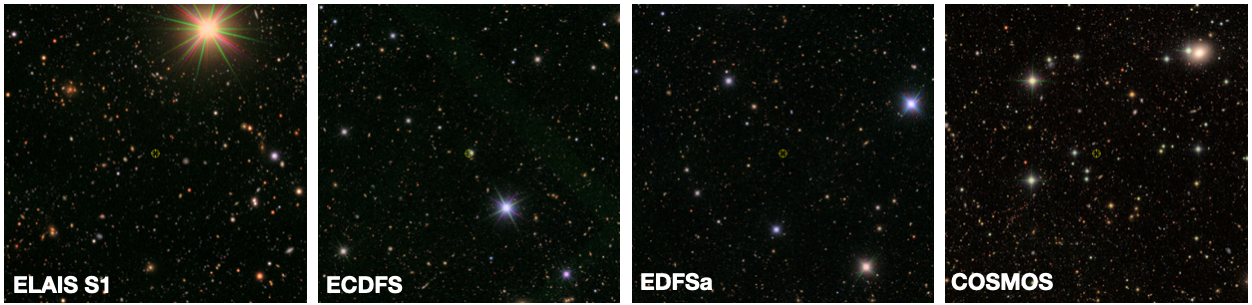

The panels show small patches of four deep drilling fields, from ELAIS-S1 on the left through ECDFS, EDFS-a and COSMOS. Rubin has observed each field many times, so we can combine the exposures into a *coadd* and pick out stars that would be lost in the noise of a single exposure. For A and B we’ll look at two much smaller pieces of the ELAIS-S1 *r*-band coadd, centred on the positions from Gaia. [Rubin deep drilling fields tutorial](https://dp2.lsst.io/tutorials/notebook/301/notebook-301-3.html#introduction)


If you’re making the cutouts and catalogue matches for the first time, open this notebook on the Rubin Science Platform with the LSST kernel, run the setup cells at the top, then set `prepare_rubin = True` below and run Part 4. Save the notebook with its outputs and keep `gaia_data/` beside it, since that’s where these cells save the images and matches you’ll need if you run the notebook again off the platform. [Rubin image cutout tutorial](https://dp2.lsst.io/tutorials/notebook/104/notebook-104-5.html)

Each cutout is 61 × 61 pixels, or about 12″ across at 0.2″ per pixel, and the circle is centred on the Gaia position with a radius of 1″ (5 pixels). Can you identify a likely Rubin counterpart inside each circle, or is there a neighbouring source close enough to make the match ambiguous? Both panels use the same brightness scale, so you can also judge by eye which of the two stars looks brighter.


In [ ]:
prepare_rubin = False  # True on the Rubin Science Platform for the first download

# RA and Dec are in degrees, as in the published Gaia candidate list.
positions = {'A': (8.29590721, -43.89209730), 'B': (8.31053446, -43.65938938)}
gaia_g = {'A': 19.75, 'B': 18.95}
stamp_files = {label: data_dir / f'sgps_{label}_dp2_r.npz' for label in positions}

In [ ]:
if prepare_rubin and not all(path.exists() for path in stamp_files.values()):
    from astropy.coordinates import SkyCoord
    from lsst.daf.butler import Butler
    from lsst.images import Box

    butler = Butler('dp2', collections='dp2')
    for label, (ra, dec) in positions.items():
        path = stamp_files[label]
        if path.exists():
            continue
        refs = butler.query_datasets('deep_coadd',
                                     where="band.name = 'r' AND patch.region OVERLAPS POINT(ra, dec)",
                                     bind={'ra': ra, 'dec': dec}, explain=False)
        for ref in refs:
            wcs = butler.get('deep_coadd.sky_projection', dataId=ref.dataId)
            xy = wcs.sky_to_pixel(SkyCoord(ra, dec, unit='deg'))
            x, y = round(xy.x), round(xy.y)
            box = Box.factory[y-30:y+31, x-30:x+31]
            bounds = butler.get('deep_coadd.bbox', dataId=ref.dataId)
            # A star near a patch edge can be on the image while part of its cutout falls off.
            if bounds.contains(box):
                pixels = butler.get(ref, parameters={'bbox': box}).image.array
                if np.isfinite(pixels[30, 30]):
                    np.savez_compressed(path, pixels=pixels, x=xy.x - box.x.start, y=xy.y - box.y.start)
                    break
        else:
            print(f'No usable DP2 r-band cutout at the position of {label}.')

In [ ]:
from astropy.visualization import AsinhStretch, ImageNormalize

MATCH_RADIUS_PX = 5  # 1 arcsec at 0.2 arcsec/pixel

stamps, centres = {}, {}
for label, path in stamp_files.items():
    if path.exists():
        with np.load(path) as stamp:
            stamps[label] = stamp['pixels']
            centres[label] = (float(stamp['x']), float(stamp['y']))

if stamps:
    # If we let imshow scale each cutout separately, the fainter star can look just as bright.
    sky_level = np.nanpercentile(np.stack(list(stamps.values())), 10)
    peak = max(np.nanmax(image[25:36, 25:36]) for image in stamps.values())
    norm = ImageNormalize(vmin=sky_level, vmax=max(peak, sky_level + 1), stretch=AsinhStretch())
    fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.4))
    for ax, label in zip(axes, positions):
        ax.set_title(f'Candidate {label} · Rubin r')
        ax.set_axis_off()
        if label in stamps:
            ax.imshow(stamps[label], origin='lower', cmap='gray', norm=norm)
            ax.add_patch(plt.Circle(centres[label], MATCH_RADIUS_PX, fill=False, color='#64D8DB', lw=1))
        else:
            ax.text(.5, .5, 'Cutout unavailable', ha='center', transform=ax.transAxes)
    plt.show()
else:
    print('The candidate cutouts will appear here after the Rubin preparation run.')

Run the catalogue cell and check how many entries in the Rubin DP2 Object catalogue fall within 1″ of each Gaia position. Where there’s a single match, the table gives the *r* magnitude that Rubin measures by fitting the point-spread function, the shape a point source has in the image. How does the measured brightness of A relative to B compare with your prediction from Gaia, and what else would you want to measure before calling either star a member of SGP-S?


In [ ]:
match_file = data_dir / 'sgps_dp2_matches.ecsv'
if prepare_rubin and not match_file.exists():
    from lsst.rsp import RSPDiscovery
    from astropy.coordinates import SkyCoord

    tap = RSPDiscovery('dp2').get_tap_client()
    rows = []
    for label, (ra, dec) in positions.items():
        query = f"""
            SELECT objectId, coord_ra, coord_dec, r_psfMag
            FROM dp2.Object
            WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec),
                           CIRCLE('ICRS', {ra}, {dec}, {1 / 3600})) = 1
        """
        found = tap.search(query).to_table()
        if len(found) == 1:
            obj = found[0]
            gaia_pos = SkyCoord(ra, dec, unit='deg')
            rubin_pos = SkyCoord(obj['coord_ra'], obj['coord_dec'], unit='deg')
            distance = gaia_pos.separation(rubin_pos).arcsec
            rows.append((label, 1, 'unique', str(obj['objectId']), distance, obj['r_psfMag']))
        else:
            status = 'no match' if len(found) == 0 else 'ambiguous'
            rows.append((label, len(found), status, '—', np.nan, np.nan))
    matches = Table(rows=rows, names=['Star', 'Count', 'Match', 'Rubin ID', 'Offset (arcsec)', 'r (mag)'])
    matches.write(match_file, format='ascii.ecsv')

if match_file.exists():
    matches = Table.read(match_file)
    matches['Gaia G (mag)'] = [gaia_g[star] for star in matches['Star']]
    matches['r − G (mag)'] = matches['r (mag)'] - matches['Gaia G (mag)']
    matches = matches['Star', 'Count', 'Match', 'Rubin ID', 'Offset (arcsec)',
                      'Gaia G (mag)', 'r (mag)', 'r − G (mag)']
    for column, fmt in {'Offset (arcsec)': '.3f', 'Gaia G (mag)': '.2f',
                        'r (mag)': '.2f', 'r − G (mag)': '+.2f'}.items():
        matches[column].format = fmt
    display(matches)
else:
    print('The catalogue matches will appear here after the Rubin preparation run.')

<details><summary>Compare with the catalogue</summary>

B is 0.80 mag brighter than A in Gaia *G*, and since their BP − RP colours differ by only 0.04 mag, we’d expect much the same difference between them in Rubin *r*. At these colours we can use *G* as a rough estimate of *r*, which puts A at about 19.7 mag and B at about 19.0 mag. Rubin measures *r* = 19.74 for A and 18.97 for B, a difference of 0.77 mag, so we receive about twice as much *r*-band flux from B.

There’s one Rubin object inside each circle, and in both cases it lies within 0.04″ of the Gaia position. That makes the identification fairly convincing, though if two objects had fallen inside a circle we’d have had to work out which one Gaia saw.

For the membership question we’d want spectra. Do the radial velocities of A and B agree with what we’d expect for the stream at those positions, and are their metallicities consistent with the stream’s metal-poor population? The published list gives a radial velocity for just one of the 36 candidates.

</details>


## Credits and further reading

The cluster exercises follow ESA’s Pleiades tutorial, and the GD-1 exercise draws on the stream analysis in Allen Downey’s *Astronomical Data in Python*, including his discussion of the Gaia row limit. The coordinates we use to follow GD-1 across the sky are from Koposov, Rix & Hogg (2010). [ESA Gaia notebooks](https://github.com/esa/gaia-jupyter-notebooks) · [Astronomical Data in Python](https://allendowney.github.io/AstronomicalData/)

Parts 1–3 use data from the European Space Agency’s Gaia mission, processed for Gaia DR3 by the Gaia Data Processing and Analysis Consortium (DPAC). [Gaia data credits](https://www.cosmos.esa.int/web/gaia-users/credits)

Yang et al. (2022) discovered SGP-S in Gaia EDR3, and the two candidates we look at in Part 4 are from Ibata et al. (2024), whose list is included in the membership tables that accompany Bonaca & Price-Whelan’s review. We use the Rubin DP2 deep coadds for the images and the DP2 Object catalogue for the photometry. [SGP-S discovery paper](https://arxiv.org/abs/2208.05176) · [Stellar streams in the Gaia era](https://doi.org/10.1016/j.newar.2024.101713) · [Rubin DP2 Object catalogue](https://dp2.lsst.io/products/catalogs/object.html)

GPT 6.2 Astra and Claude Opus 5.5 helped with the notebook.
